# INTEGRACIÓN DE ROMBERG

# Fundamentos

Anteriormente planteamos el problema de la integración numérica. Muchos de los métodos expuestos en análisis numérico tienen una cierta exactitud, cuando la función a integrar es más compleja tiende a tener un error mayor. Por fortuna, hay un método efectivo para tener un resultado más certero durante la obtención de una integral numérica; antes hay que explicar dos conceptos base.

Sabemos que para la regla de Simpson dada por

$$\int_{x_1}^{x_2}f(x)\,dx=\frac{h}{3}[f(x_0)+4f(x_1)+f(x_2)]-\frac{h^5}{90}f^{IV}(\xi)$$ donde $$x_0<\xi<x_2$$ y $$x_1=\frac{x_0+x_2}{2}$$

Aunque la regla es buena puede presentar errores grandes para funciones con cambios bruscos de comportamiento, por lo que podemos hacer una extensión a esta regla. Supóngase que tenemos un intervalo cualquiera $[a,b]$, aplicamos Simpson y todo bien, pero, podemos hacer algo mejor; ¿qué tal si dividimos en dos segmentos iguales a $[a,b]$ (es decir, obtendremos a $[a,b_1]$ y $[b_1,b]$, donde $b_1=\frac{a+b}{2}$)? y ahora aplicamos Simpson a cada intervalo con la misma integral, pero resuelta en dos integrales, esto nos acerca mejor a un resultado óptimo, ¿y si fueran tres particiones iguales del intervalo $[a,b]$? de nuevo, aplicamos Simpson a las tres integrales seccionaadas, y el resultado sería mucho mejor, ¿y si fueran $n$ particiones? es decir, de $[a,b]$ tendremos a $[a,b_1]$, $[b_1,b_2]$, $[b_2,b_3]$, $...$, $[b_{n-1},b_n]$, $[b_n,b]$, esto es a grandes rasgos lo hablado en el código de la regla compuesta de Simpson, si consideramos que $b_n=x_j=a+jh$ con $j=1,...,n$. Al final tendremos $n$ particiones iguales, y eso nos lleva a una aproximaciión mejor, y de ahí, la regla de Simpson se vuelve

$$\int_a^b f(x)\,dx=\frac{h}{3}[f(a)+2\sum_{j=1}^{\frac{n}{2}-1}f(x_{2j})+4\sum_{j=1}^{\frac{n}{2}}f(x_{2j-1})+f(b)]-\frac{b-a}{180}h^4f^{IV}(\mu)$$
con $$x_0<\mu<x_2$$

Y no solo es la regla de Simpson; existen fórmulas de otros órdenes como la trapezoidal, con fórmula

$$\int_a^b f(x)\,dx=\frac{h}{2}[f(a)+2\sum_{j=1}^{n-1}f(x_{j})+f(b)]-\frac{b-a}{12}h^2f^{II}(\mu)$$
con $$x_0<\mu<x_1$$
y siguen el mismo fundamento.

El segundo tema tiene que ver con la extrapolación de Richarsdon. La idea de esta técnica es asi, suponemos que tenemos un método conocido de orden menor de exactitud (esto es muy importante), podemos evitarnos tiempo para cálculos de errores y aprovechar nuestros resultados obtenidos a partir de dicho método si generamos una relación de estos, y no solo eso, sino también mejorar los resultados. Es de suma importancia ya que no solo tiene aplicación para un solo método, sino existen muchas aplicaciones en distintos métodos numéricos.

Volviendo a nuestro problema principal con la integración numérica; tenemos a distintas reglas compuestas de integración, supóngase que tenemos distintos resultados de $\int_a^b f(x)\, dx$ aplicando sucesivamente de 1 a $n$ subintervalos divididos igualmente (obviamente convergiendo uno mejor que el otro), si ordenamos estos resultados $R_{1,1}, R_{2,1}, R_{3,1},..., R_{n,1}$ podemos utilizarlos para tener una mejor aproximación a la integral usando la extrapolación de Richarsdon. Esta tecnica explica que si queremos aproximarnos a $M$, constante desconocida, su error de truncamiento tiene la forma

$$M-N_1(h)=K_1h+K_2h^2+K_3h^3+...$$

siendo $N_1(h)$ una aproximación inicial a $M$ y las $K$ son desconocidas. Si despejamos $M$ entonces

$$M=N_1(h)+K_1h+K_2h^2+K_3h^3+...=N_1(h)+\sum_{j=1}^{m-1}K_{j}h^{j}$$

en otras palabras, lo que se anuncia es que la $M$ se obtiene de una aproximación inicial menor más un término de error, llamemos esto $O(h)$. Si ajustamos la ecuación con la fórmula trapezoidal, su término de error tambien se puede representar de la forma

$$K_1h^2+K_2h^4+K_3h^6+...$$

y en general, la integral se aproxima a una M, y tiene la siguiente aproximación de error

$$\sum_{j=1}^{m-1}K_{j}h^{2j}+O(h^{2m})$$

por lo que es candidato perfecto para aplicar la extrapolación de Richardson. Englobando todo en una pieza, para las primeras aproximaciones de $R_{1,1}$ a $R_{n,1}$, resultados de una regla de orden menor, la integración de Romberg es un método que "pule" los resultados anteriores y los acerca a un mejor resultado sin necesidad de usar tantas iteraciones en el método; una vez teniendo las primeras iteraciones del método usado se usa la regla siguiente para armar una tabla matriz diagonal

$$R_{k,j}=R_{k,j-1}+\frac{1}{4^{j-1}-1}(R_{k,j-1}-R_{k-1,j.1})$$ para $$k=j, j+1,...$$

y la tabla matriz es la siguiente

$$\begin{array}{c|c|c}n&R_{n,1}&R_{n,2}&...&R_{n,n}\\
\hline
1&R_{1,1}& & & \\
2&R_{2,1}&R_{2,2}\\
\vdots&\vdots&\vdots&\ddots\\
n&R_{n,1}&R_{n,2}&...&R_{n,n}
\end{array}$$

En seguida se expondrá el código base para este método

## Código para la integración de Romberg

In [2]:
import numpy as np #definimos de una vez la libreria para nuestras funciones

def f(x): #creamos una función
    return np.sin(x) #nos devolverá la función seno para nuestro ejemplo más adelante

In [14]:
def R(f, a, b, n):#definiremos nuestra función para la integración de Romberg
    h=b-a #nuestra primera h para la primera iteracion en regla del trapecio compuesta
    tR=[[0.0 for j in range(n)]for i in range(n)] #aqui guardaremos nuestro resultado final en forma matricial
    tR[0][0]=h/2*(f(a)+f(b)) #estamos haciendo a R_1,1
    print(tR[0][0]) #imprime el primer valor de la tabla matriz
    for i in range(2,n+1): #creamos un ciclo para los resultados de la tabla matriz
        S=0 #contador para la suma
        for k in range(1,2**(i-2)+1): #para la aproximación de la sumatoria en R_2,1
            S+= f(a+(k-0.5)*h)

        tR[i-1][0]=0.5*(tR[i-2][0]+h*S) #resultado de R_2,1
        for j in range(2,i+1):# para la generacion de la extrapolación 
            tR[i-1][j-1]=(tR[i-1][j-2]+(tR[i-1][j-2]-tR[i-2][j-2])/(4**(j-1)-1))

        h=h/2 #se genera una nueva h y se repite el ciclo n veces

    return tR #nos devolverá el arreglo que forma parte de la tabla matricial de R_n,n
            
        
    

## Ejemplo práctico.

Demostrar con la integración de Romberg

$$I=\int_0^{\pi}\sin(x)\,dx=2$$

Solución. Por T.F.C. podemos decir claramente que $I=2$, pero hablando del método, nuestra tabla matriz generada por nuestro código deberia tener un comportamiento convergente en torno a $I=2$. Lo veremos a continuación con la impresión de la tabla:

In [17]:
for fila in R(f,0,np.pi,5):
    print(fila) #con este pequeño codigo estoy llamando a la función para la integración de Romberg y además imprimo los resultados dada f(x)=sen(x) en [0,3.14159...] con n=5

1.9236706937217898e-16
[np.float64(1.9236706937217898e-16), 0.0, 0.0, 0.0, 0.0]
[np.float64(1.5707963267948966), np.float64(2.0943951023931953), 0.0, 0.0, 0.0]
[np.float64(1.8961188979370398), np.float64(2.0045597549844207), np.float64(1.9985707318238357), 0.0, 0.0]
[np.float64(1.974231601945551), np.float64(2.000269169948388), np.float64(1.999983130945986), np.float64(2.000005549979671), 0.0]
[np.float64(1.9935703437723395), np.float64(2.0000165910479355), np.float64(1.999999752454572), np.float64(2.0000000162880416), np.float64(1.9999999945872902)]


En la tabla matriz podemos observar que empezamos con una aproximación un poco mala, pero a medida que se itera el resultado se acerca a 2, el último término, $R_{5,5}$, es el que se acerca ya bastante a 2, que era lo que queríamos demostrar con este método. Para darnos una idea del resultado encontrado veamos el siguiente gráfico:

## Gráfico de f(x)

Text(0.5, 0.9, 'I= 2')

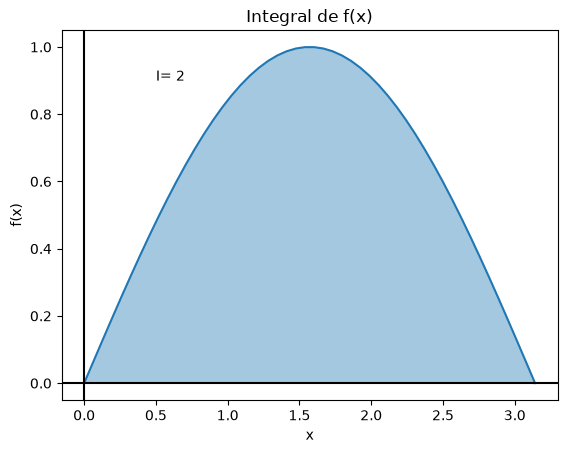

In [29]:
import matplotlib.pyplot as plt #librería para la generación de gráficas

x=np.linspace(0,np.pi) #genera una reticula o una partición
plt.plot(x,f(x)) #dibuja la gráfica de y=f(x)
plt.xlabel('x') #un pequeño letrero que indica los valores de x
plt.ylabel('f(x)') #un pequeño letrero que indica los valores de f(x)
plt.title('Integral de f(x)') #Encabezado de la gráfica
plt.axhline(y=0, color = 'black') #pinta un eje X
plt.axvline(x=0, color = 'black') #pinta un eje Y
I=2
a_I=np.linspace(0,np.pi) #es importante esto, funciona como indicador para el área que se quiere sombrear de la integral
plt.fill_between(a_I, f(a_I), 0, alpha=0.4) #colorea el area bajo la curva de f(x) de 0 a pi
plt.text(0.5, 0.9, f"I= {I}") #aprovechamos la memoria guardada del resultado de I y hacemos incapié al resultado obtenido de la integral en la gráfica


Recordemos que una integral, geométricamente es el area bajo la curva de $f(x)$, en este caso podemos observar que en un principio, la regla trapezoidal es mala, pero cuando se extiende y además se agrega una extrapolación podemos tener resultados buenos y mejores, e incluso ahorrarnos algo de trabajo.
    

Por último, deducimos, tanto por T.F.C y por la integración de Romberg que efectivamente

$$I=\int_0^{\pi}\sin(x)\,dx=2$$